### Multivariate Analysis

#### Keith R. Holdaway FGS

### Part 01

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# Generate synthetic petrophysical data
np.random.seed(42)
n_samples = 1000

data = {
    'DEPTH': np.arange(n_samples),
    'GR': np.random.normal(60, 15, n_samples),  # Gamma Ray (API)
    'NPHI': np.random.uniform(0.1, 0.3, n_samples),  # Neutron Porosity (v/v)
    'RHOB': 2.65 - 0.9*np.random.uniform(0.1, 0.3, n_samples) + np.random.normal(0, 0.05, n_samples),
    'RT': 10**(2 - 0.5*np.random.uniform(0.1, 0.3, n_samples) + np.random.normal(0, 0.1, n_samples)),
    'Facies': np.random.choice(['Sandstone','Shale','Carbonate'], 
                             p=[0.6,0.3,0.1], size=n_samples),
    'PERM': 100 * np.random.uniform(0.1, 0.3, n_samples)**2  # Permeability (mD)
}
df = pd.DataFrame(data)

# Add synthetic fluid zones
df['Zone'] = pd.cut(df['DEPTH'], bins=5, labels=['Zone1','Zone2','Zone3','Zone4','Zone5'])

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# Generate synthetic petrophysical data
np.random.seed(42)
n_samples = 1000

data = {
    'DEPTH': np.arange(n_samples),
    'GR': np.random.normal(60, 15, n_samples),  # Gamma Ray (API)
    'NPHI': np.random.uniform(0.1, 0.3, n_samples),  # Neutron Porosity (v/v)
    'RHOB': 2.65 - 0.9*np.random.uniform(0.1, 0.3, n_samples) + np.random.normal(0, 0.05, n_samples),
    'RT': 10**(2 - 0.5*np.random.uniform(0.1, 0.3, n_samples) + np.random.normal(0, 0.1, n_samples)),
    'Facies': np.random.choice(['Sandstone','Shale','Carbonate'], 
                             p=[0.6,0.3,0.1], size=n_samples),
    'PERM': 100 * np.random.uniform(0.1, 0.3, n_samples)**2  # Permeability (mD)
}
df = pd.DataFrame(data)

# Add synthetic fluid zones
df['Zone'] = pd.cut(df['DEPTH'], bins=5, labels=['Zone1','Zone2','Zone3','Zone4','Zone5'])

# Pair Plots (Scatterplot Matrix)

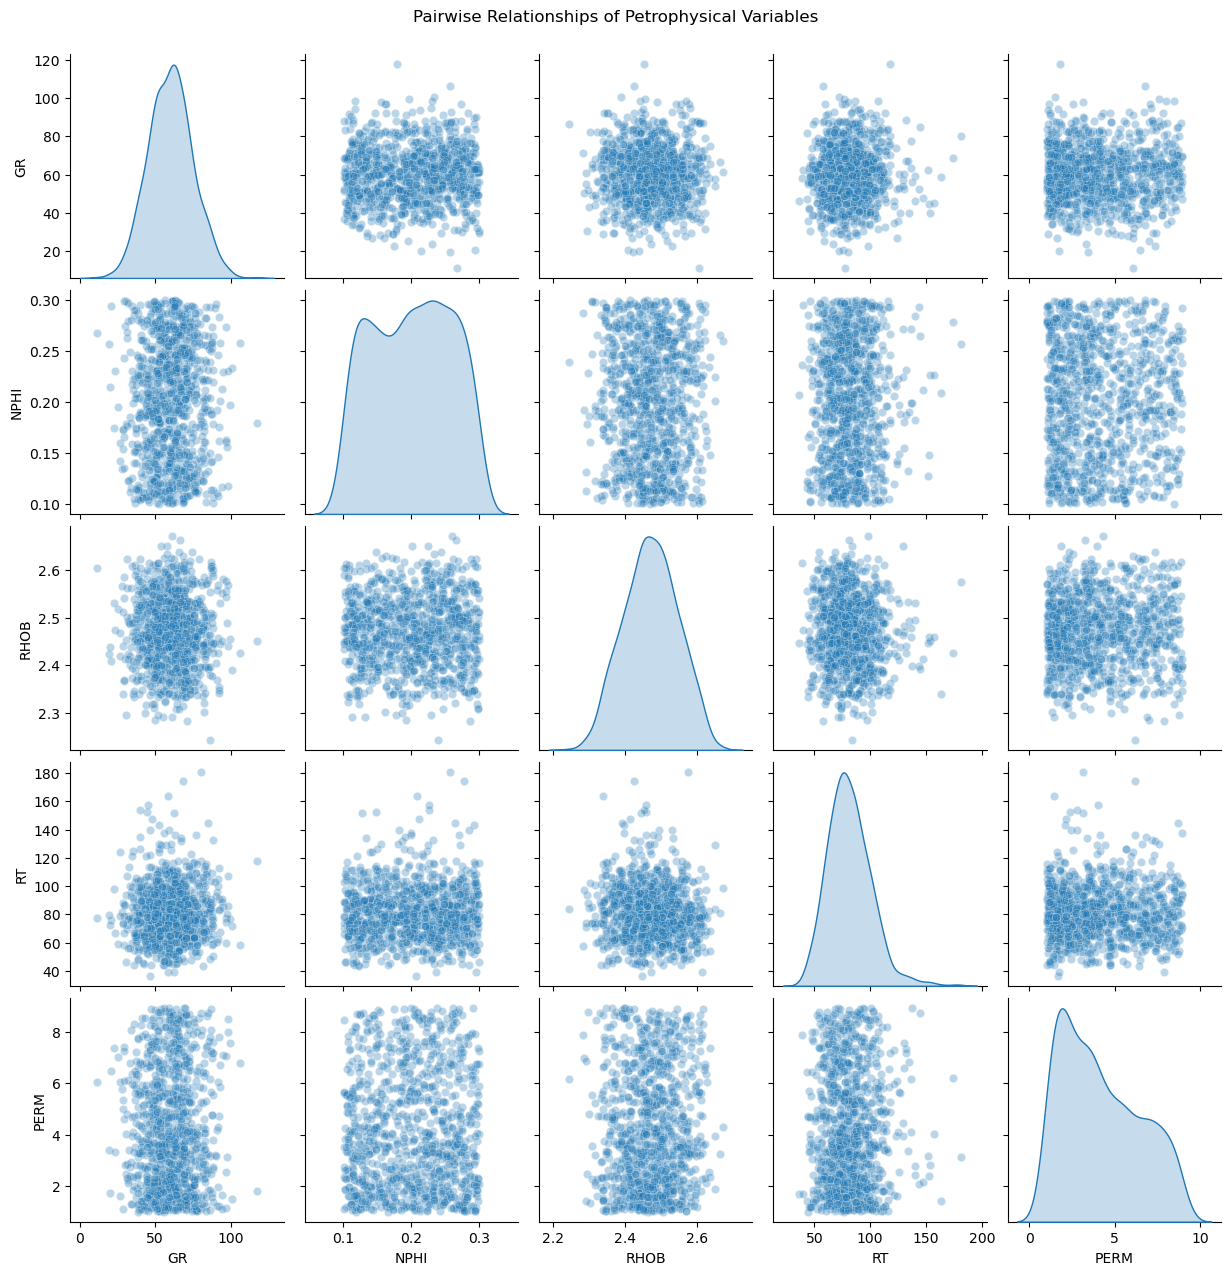

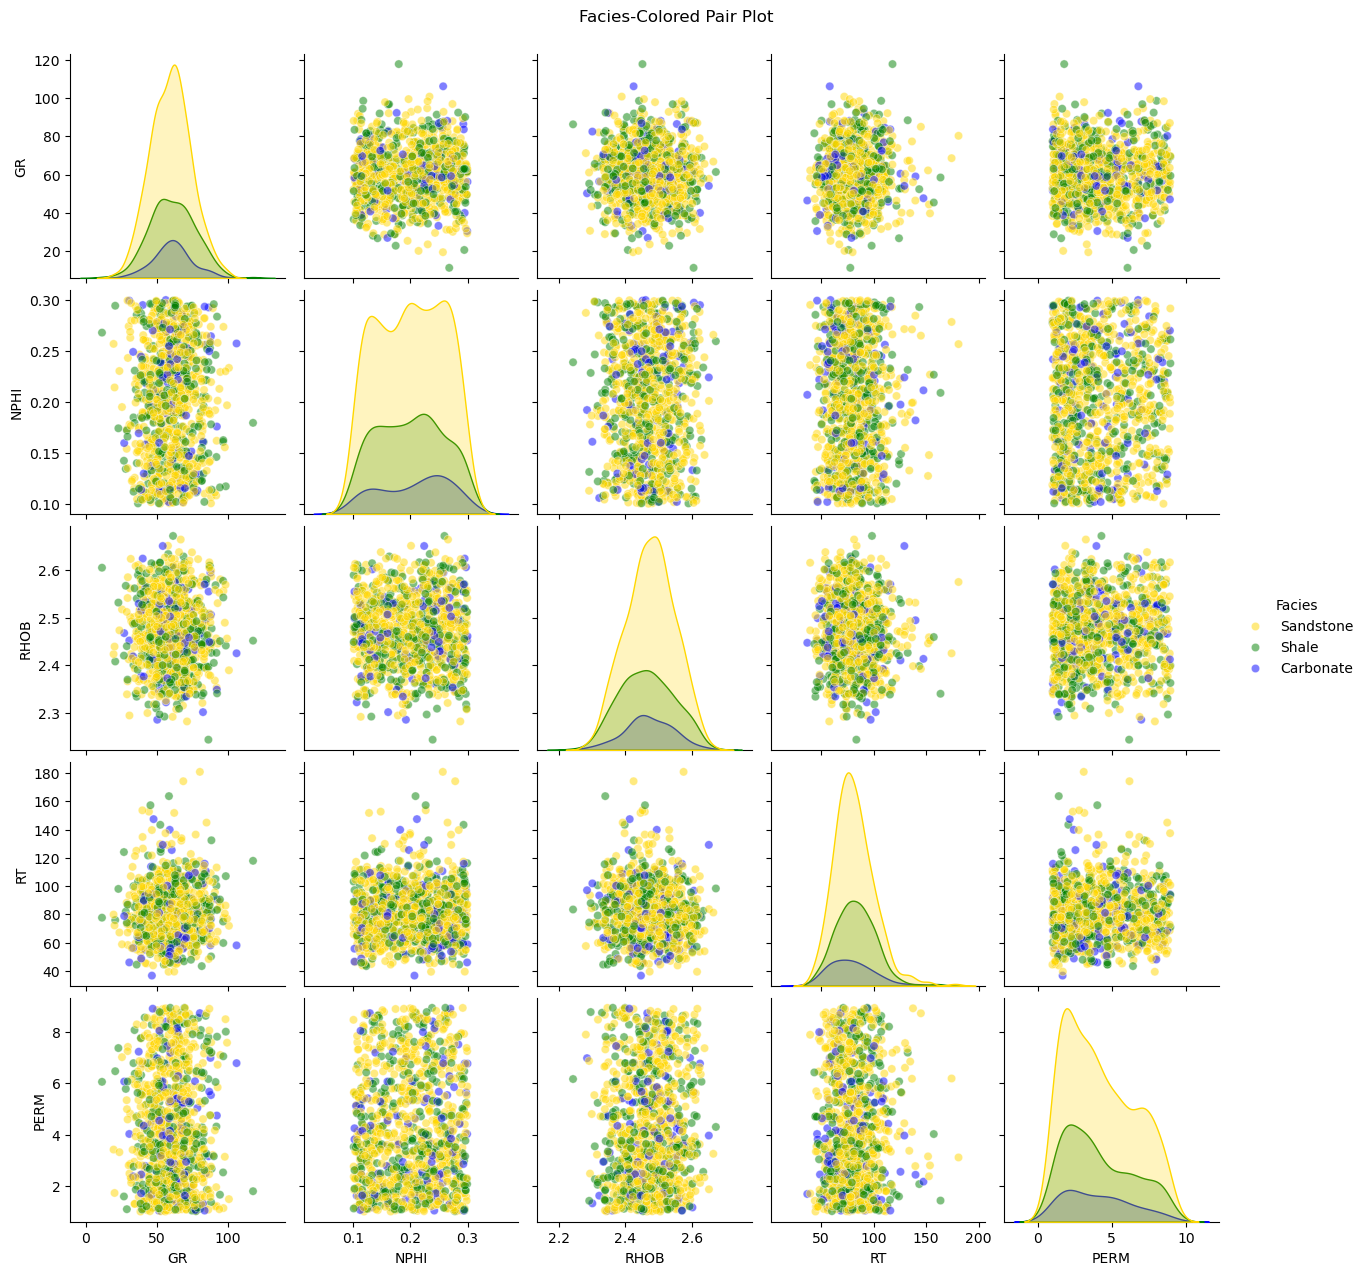

In [3]:
# Select key continuous variables
num_vars = ['GR', 'NPHI', 'RHOB', 'RT', 'PERM']

# Basic pair plot
sns.pairplot(df[num_vars], diag_kind='kde', plot_kws={'alpha':0.3})
plt.suptitle('Pairwise Relationships of Petrophysical Variables', y=1.02)
plt.show()

# Enhanced pair plot colored by facies
sns.pairplot(df, vars=num_vars, hue='Facies', 
            palette={'Sandstone':'gold', 'Shale':'green', 'Carbonate':'blue'},
            diag_kind='kde', plot_kws={'alpha':0.5})
plt.suptitle('Facies-Colored Pair Plot', y=1.02)
plt.show()

# Correlation Heatmap

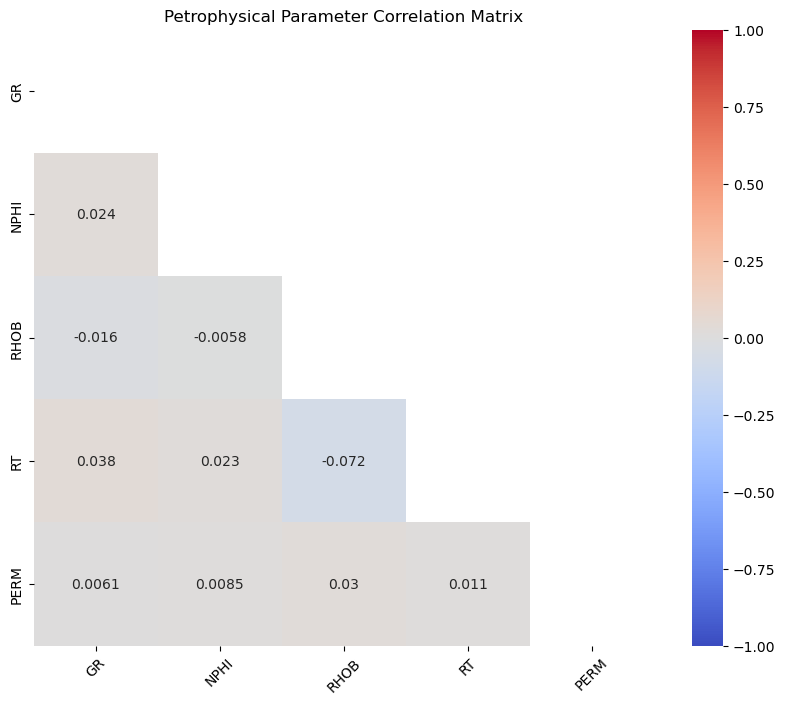

In [4]:
plt.figure(figsize=(10,8))
corr = df[num_vars].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', 
           vmin=-1, vmax=1, center=0,
           mask=np.triu(np.ones_like(corr, dtype=bool)))
plt.title('Petrophysical Parameter Correlation Matrix')
plt.xticks(rotation=45)
plt.show()

# Parallel Coordinates Plot

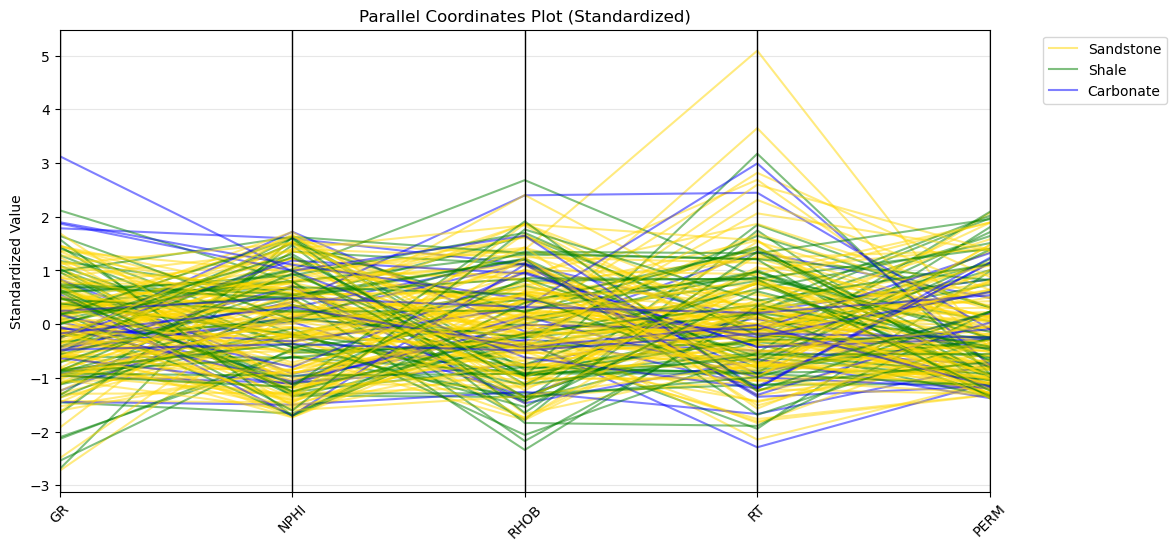

In [5]:
from pandas.plotting import parallel_coordinates

# Standardize data for better visualization
scaler = StandardScaler()
df_std = pd.DataFrame(scaler.fit_transform(df[num_vars]), columns=num_vars)
df_std['Facies'] = df['Facies']

plt.figure(figsize=(12,6))
parallel_coordinates(df_std.sample(200), 'Facies', 
                    color=['gold','green','blue'], alpha=0.5)
plt.title('Parallel Coordinates Plot (Standardized)')
plt.ylabel('Standardized Value')
plt.xticks(rotation=45)
plt.legend(bbox_to_anchor=(1.05,1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.show()

# 3D Scatter Plot

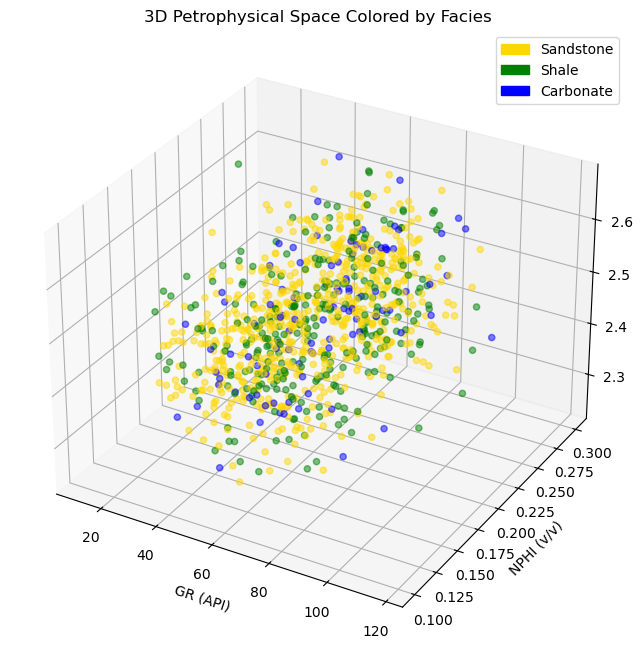

In [6]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10,8))
ax = fig.add_subplot(111, projection='3d')

# Color by facies
colors = {'Sandstone':'gold', 'Shale':'green', 'Carbonate':'blue'}
df['color'] = df['Facies'].map(colors)

# Plot
sc = ax.scatter(df['GR'], df['NPHI'], df['RHOB'], 
               c=df['color'], alpha=0.5, s=20)

# Add legend
import matplotlib.patches as mpatches
patches = [mpatches.Patch(color=c, label=f) for f,c in colors.items()]
ax.legend(handles=patches)

ax.set_xlabel('GR (API)')
ax.set_ylabel('NPHI (v/v)')
#ax.set_zlabel('RHOB (g/cc)')
ax.set_title('3D Petrophysical Space Colored by Facies')
plt.show()

# Faceted Multivariate Displays

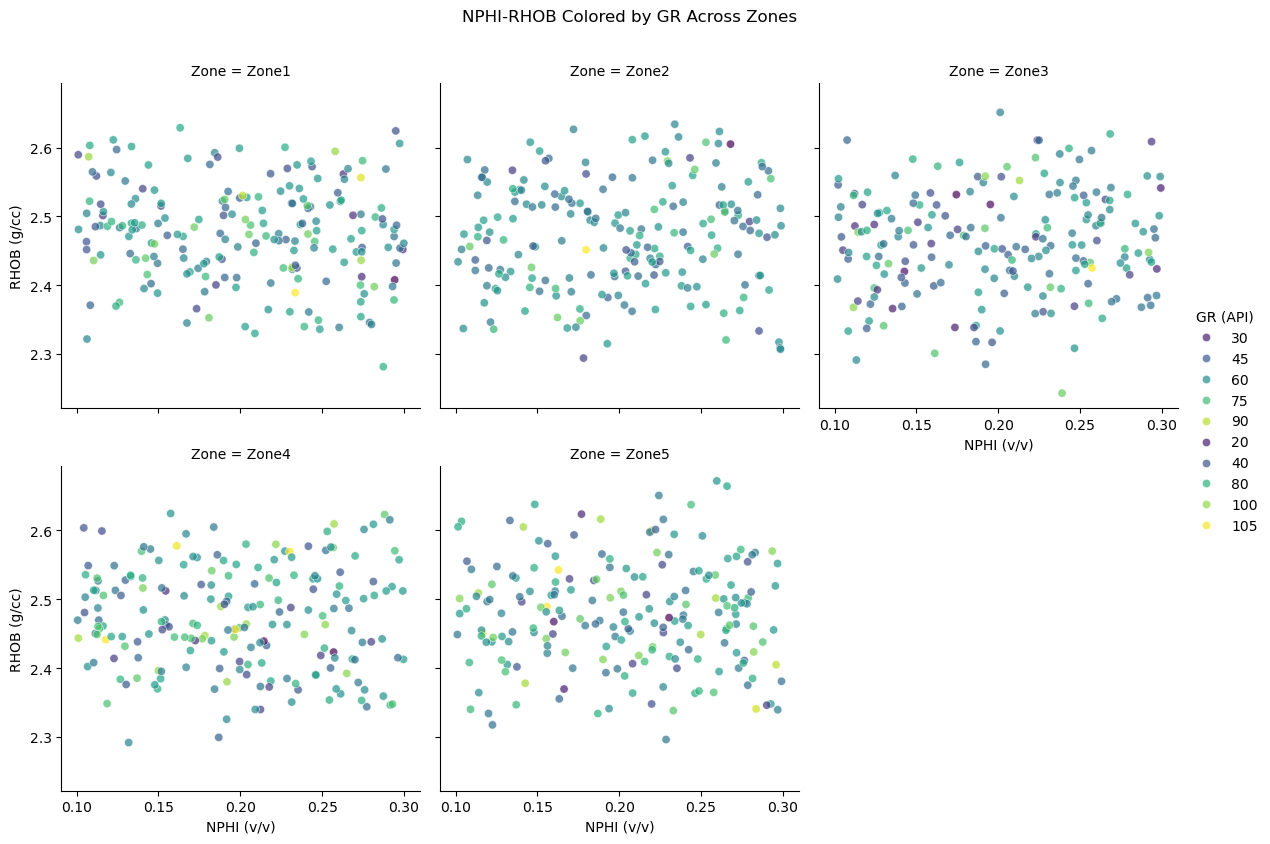

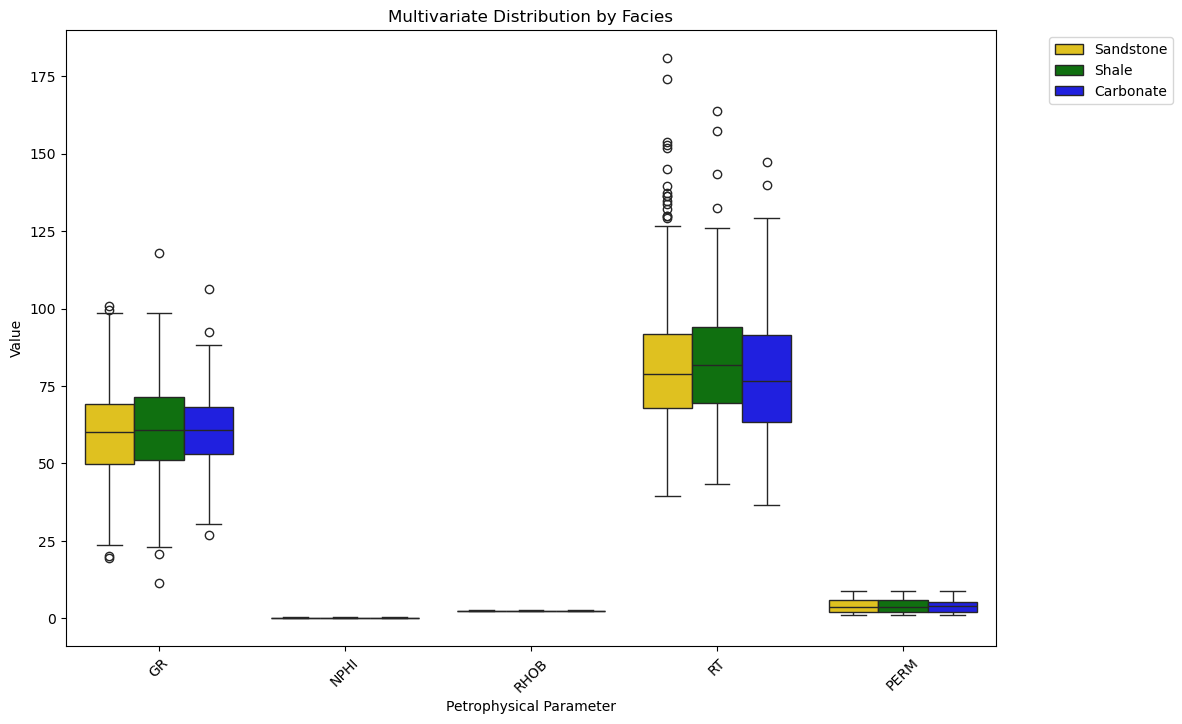

In [7]:
# Faceted scatter plots by zone
g = sns.FacetGrid(df, col='Zone', col_wrap=3, height=4)
g.map(sns.scatterplot, 'NPHI', 'RHOB', 'GR', 
      palette='viridis', alpha=0.7)
g.set_axis_labels('NPHI (v/v)', 'RHOB (g/cc)')
g.fig.suptitle('NPHI-RHOB Colored by GR Across Zones', y=1.05)
g.add_legend(title='GR (API)')
plt.show()

# Boxplot matrix by facies
plt.figure(figsize=(12,8))
sns.boxplot(data=df.melt(id_vars=['Facies'], 
                      value_vars=num_vars), 
          x='variable', y='value', hue='Facies',
          palette={'Sandstone':'gold', 'Shale':'green', 'Carbonate':'blue'})
plt.title('Multivariate Distribution by Facies')
plt.xlabel('Petrophysical Parameter')
plt.ylabel('Value')
plt.xticks(rotation=45)
plt.legend(bbox_to_anchor=(1.05,1), loc='upper left')
plt.show()

# Advanced: Radar Chart for Zone Comparisons

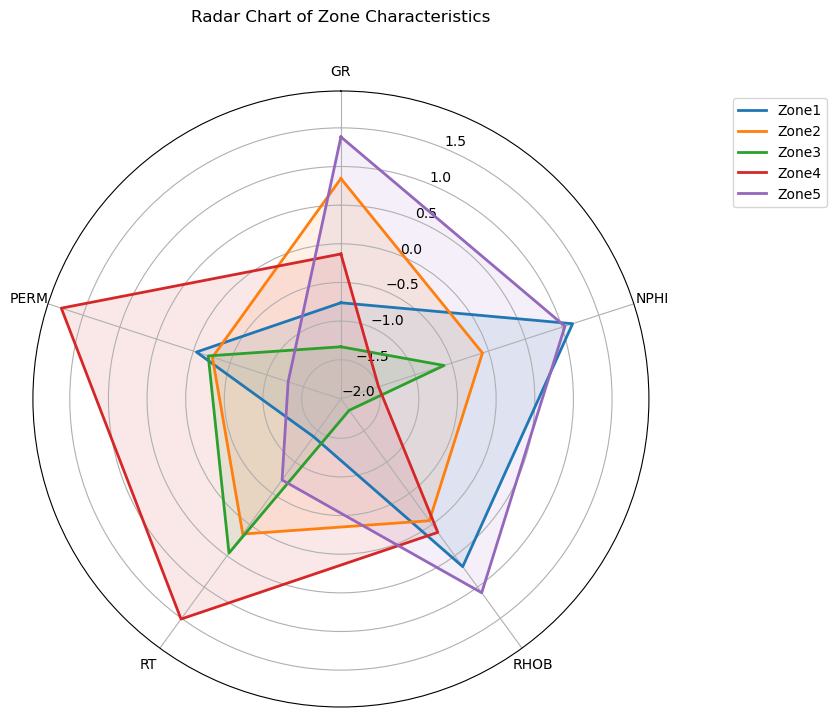

In [9]:
from math import pi

# Calculate zone averages
zone_means = df.groupby('Zone', observed=True)[num_vars].mean()

# Standardize for radar chart
zone_std = pd.DataFrame(scaler.fit_transform(zone_means), 
                      columns=zone_means.columns, 
                      index=zone_means.index)

# Plot radar chart
categories = list(zone_std.columns)
N = len(categories)

angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]

plt.figure(figsize=(8,8))
ax = plt.subplot(111, polar=True)
ax.set_theta_offset(pi/2)
ax.set_theta_direction(-1)
plt.xticks(angles[:-1], categories)

for zone in zone_std.index:
    values = zone_std.loc[zone].values.flatten().tolist()
    values += values[:1]
    ax.plot(angles, values, linewidth=2, linestyle='solid', label=zone)
    ax.fill(angles, values, alpha=0.1)

plt.title('Radar Chart of Zone Characteristics', y=1.1)
plt.legend(loc='upper right', bbox_to_anchor=(1.3,1))
plt.show()

### Part 02 - Normalization

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from math import pi

# Set up plotting style
plt.style.use('seaborn-v0_8')
print("=== Radar Charts for Petrophysical Zone Comparison ===\n")

=== Radar Charts for Petrophysical Zone Comparison ===



#### Creating Synthetic Zone Data
Let's create realistic petrophysical data for different lithofacies:

In [11]:
# Create synthetic zone data representing different lithofacies
np.random.seed(42)

zone_data = {
    'Clean Sandstone': {
        'GR': 25 + np.random.normal(0, 5, 50),      # Low GR (25-35 API)
        'RHOB': 2.25 + np.random.normal(0, 0.1, 50), # Moderate density
        'NPHI': 0.28 + np.random.normal(0, 0.03, 50), # Good porosity
        'DT': 65 + np.random.normal(0, 5, 50),       # Moderate sonic
        'RESISTIVITY': 20 + np.random.exponential(10, 50), # Moderate-high resistivity
        'VSH': 0.05 + np.random.normal(0, 0.02, 50)  # Low clay content
    },
    'Shaly Sand': {
        'GR': 65 + np.random.normal(0, 8, 50),      # Moderate GR
        'RHOB': 2.35 + np.random.normal(0, 0.08, 50), # Higher density
        'NPHI': 0.18 + np.random.normal(0, 0.04, 50), # Reduced porosity
        'DT': 85 + np.random.normal(0, 6, 50),       # Higher sonic
        'RESISTIVITY': 8 + np.random.exponential(5, 50), # Lower resistivity
        'VSH': 0.25 + np.random.normal(0, 0.05, 50)  # Moderate clay content
    },
    'Shale': {
        'GR': 110 + np.random.normal(0, 10, 50),    # High GR
        'RHOB': 2.45 + np.random.normal(0, 0.06, 50), # High density
        'NPHI': 0.35 + np.random.normal(0, 0.05, 50), # High neutron porosity
        'DT': 120 + np.random.normal(0, 8, 50),      # High sonic
        'RESISTIVITY': 2 + np.random.exponential(1, 50), # Low resistivity
        'VSH': 0.85 + np.random.normal(0, 0.08, 50)  # High clay content
    },
    'Carbonate': {
        'GR': 20 + np.random.normal(0, 4, 50),      # Very low GR
        'RHOB': 2.55 + np.random.normal(0, 0.12, 50), # High density
        'NPHI': 0.08 + np.random.normal(0, 0.02, 50), # Low porosity
        'DT': 48 + np.random.normal(0, 4, 50),       # Low sonic (fast)
        'RESISTIVITY': 50 + np.random.exponential(20, 50), # High resistivity
        'VSH': 0.03 + np.random.normal(0, 0.01, 50)  # Very low clay content
    }
}

# Calculate mean values for each zone
zone_means = {}
for zone, logs in zone_data.items():
    zone_means[zone] = {log: np.mean(values) for log, values in logs.items()}

# Create DataFrame for easier handling
df_zones = pd.DataFrame(zone_means).T

print("Mean Petrophysical Properties by Zone:")
print(df_zones.round(3))

Mean Petrophysical Properties by Zone:
                      GR   RHOB   NPHI       DT  RESISTIVITY    VSH
Clean Sandstone   23.873  2.252  0.279   65.419       29.706  0.049
Shaly Sand        66.355  2.354  0.184   84.293       12.232  0.250
Shale            111.582  2.441  0.344  120.719        3.201  0.863
Carbonate         21.496  2.558  0.081   48.312       69.239  0.032


#### Basic Radar Chart Implementation


Creating Basic Radar Chart...


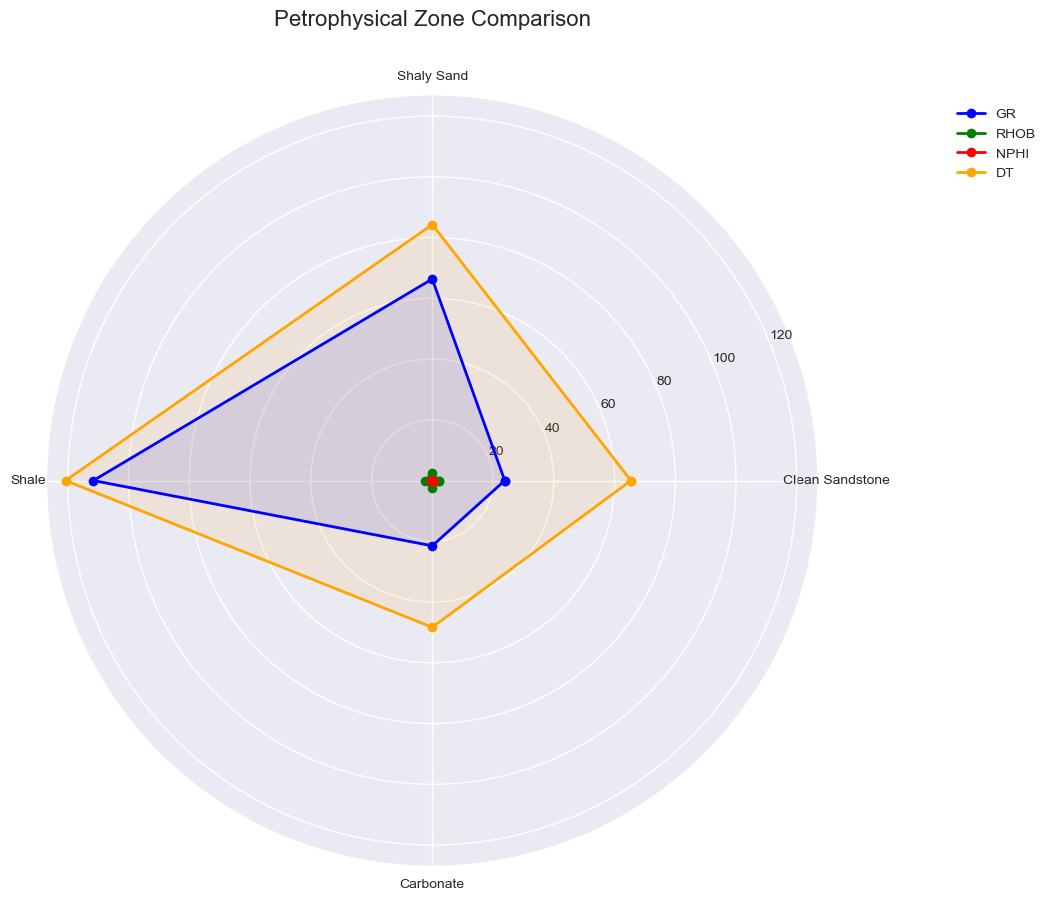

In [12]:
def create_basic_radar_chart(zone_means, title="Petrophysical Zone Comparison"):
    """
    Create a basic radar chart for zone comparison
    """
    # Parameters
    categories = list(zone_means.keys())
    zones = list(zone_means[categories[0]].keys())
    N = len(categories)
    
    # What will be the angle of each axis in the plot
    angles = [n / float(N) * 2 * pi for n in range(N)]
    angles += angles[:1]  # Complete the circle
    
    # Initialize the radar chart
    fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(projection='polar'))
    
    # Plot each zone
    colors = ['blue', 'green', 'red', 'orange']
    for i, (zone, color) in enumerate(zip(zones, colors)):
        values = [zone_means[cat][zone] for cat in categories]
        values += values[:1]  # Complete the circle
        
        # Plot the line
        ax.plot(angles, values, 'o-', linewidth=2, label=zone, color=color)
        ax.fill(angles, values, alpha=0.1, color=color)
    
    # Add category labels
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(categories)
    
    # Add grid and legend
    ax.grid(True)
    ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.0))
    plt.title(title, size=16, y=1.08)
    
    return fig, ax

print("\nCreating Basic Radar Chart...")
fig, ax = create_basic_radar_chart(zone_means)
plt.show()

#### The Problem: Different Scales and Units
Why the basic chart doesn't work well:

GR ranges: 20-110 API

RHOB ranges: 2.25-2.55 g/cc

NPHI ranges: 0.08-0.35 v/v

RESISTIVITY ranges: 2-50 ohm-m

In [13]:
print("\n=== THE SCALING PROBLEM ===")
print("Each log has different units and ranges:")
for log in ['GR', 'RHOB', 'NPHI', 'RESISTIVITY']:
    min_val = df_zones[log].min()
    max_val = df_zones[log].max()
    print(f"{log}: {min_val:.2f} to {max_val:.2f}")

print("\nThis distorts the radar chart - we need normalization!")


=== THE SCALING PROBLEM ===
Each log has different units and ranges:
GR: 21.50 to 111.58
RHOB: 2.25 to 2.56
NPHI: 0.08 to 0.34
RESISTIVITY: 3.20 to 69.24

This distorts the radar chart - we need normalization!


#### Normalized Radar Charts for Fair Comparison


Creating Normalized Radar Chart...


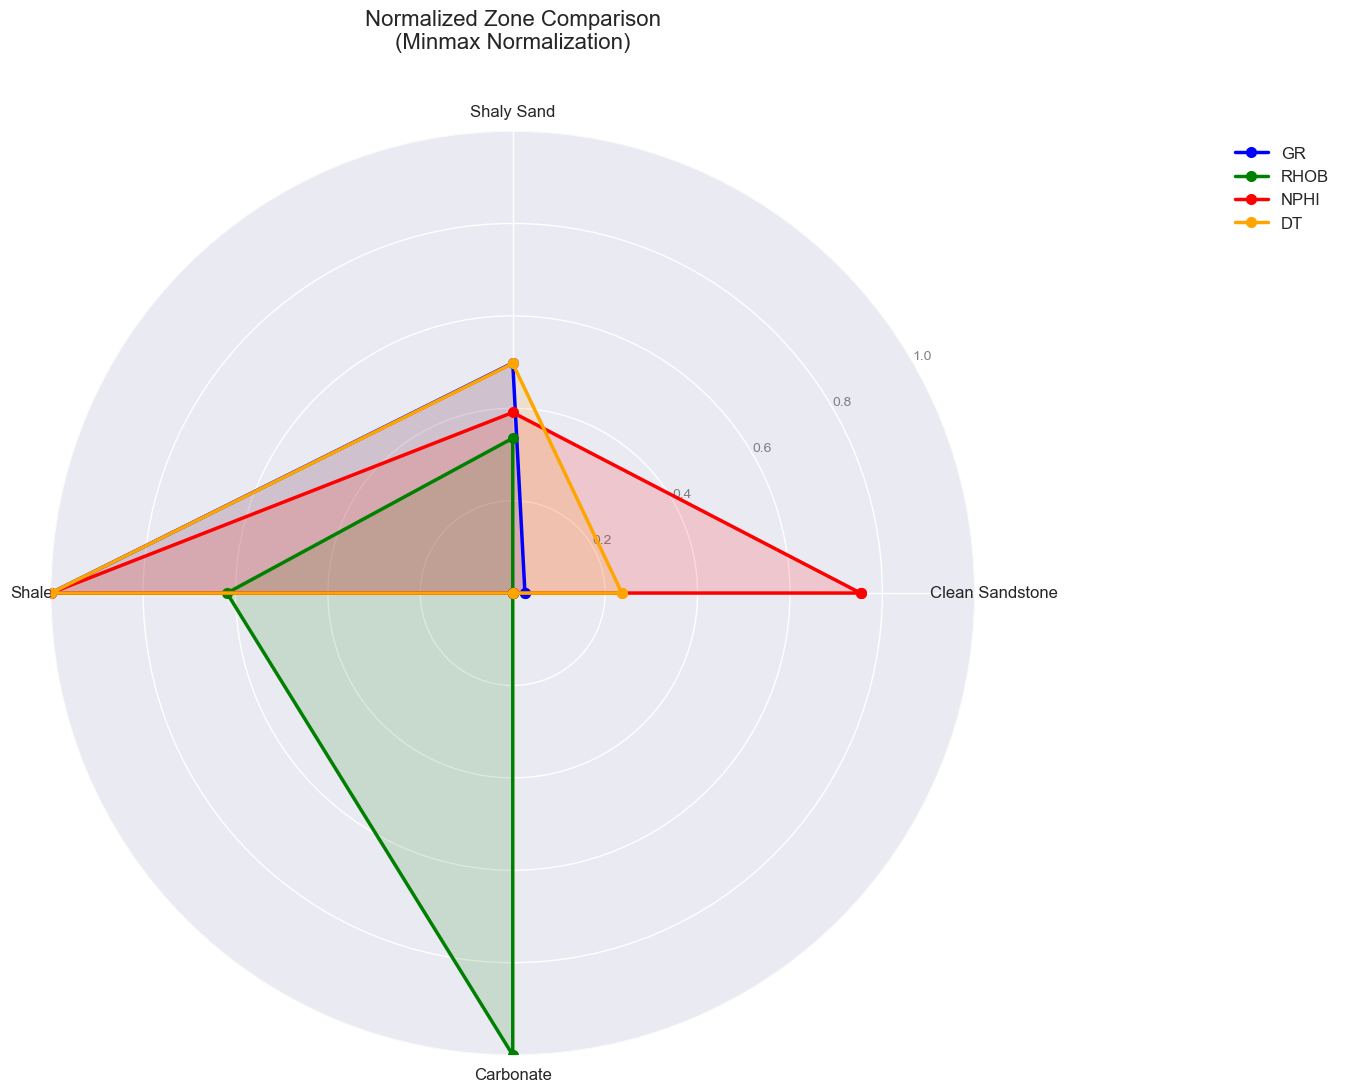

In [14]:
def create_normalized_radar_chart(zone_means, normalization='minmax', title="Normalized Zone Comparison"):
    """
    Create radar chart with normalized data for fair comparison
    """
    categories = list(zone_means.keys())
    zones = list(zone_means[categories[0]].keys())
    N = len(categories)
    
    angles = [n / float(N) * 2 * pi for n in range(N)]
    angles += angles[:1]
    
    fig, ax = plt.subplots(figsize=(12, 12), subplot_kw=dict(projection='polar'))
    
    # Normalize data
    normalized_data = {}
    for zone in zones:
        values = [zone_means[cat][zone] for cat in categories]
        
        if normalization == 'minmax':
            # Min-max normalization to [0,1]
            min_val = min(values)
            max_val = max(values)
            normalized = [(x - min_val) / (max_val - min_val) for x in values]
        elif normalization == 'zscore':
            # Z-score normalization
            mean_val = np.mean(values)
            std_val = np.std(values)
            normalized = [(x - mean_val) / std_val for x in values]
        else:
            normalized = values
        
        normalized += normalized[:1]
        normalized_data[zone] = normalized
    
    # Plot each zone
    colors = ['blue', 'green', 'red', 'orange']
    for i, (zone, color) in enumerate(zip(zones, colors)):
        values = normalized_data[zone]
        ax.plot(angles, values, 'o-', linewidth=2.5, label=zone, color=color, markersize=8)
        ax.fill(angles, values, alpha=0.15, color=color)
    
    # Add labels and formatting
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(categories, fontsize=12)
    
    # Add radial labels
    ax.set_rlabel_position(30)
    plt.yticks([0.2, 0.4, 0.6, 0.8, 1.0], ["0.2", "0.4", "0.6", "0.8", "1.0"], color="grey", size=10)
    ax.set_ylim(0, 1)
    
    ax.grid(True)
    ax.legend(loc='upper right', bbox_to_anchor=(1.4, 1.0), fontsize=12)
    plt.title(f"{title}\n({normalization.capitalize()} Normalization)", size=16, y=1.08)
    
    return fig, ax

print("\nCreating Normalized Radar Chart...")
fig, ax = create_normalized_radar_chart(zone_means, normalization='minmax')
plt.show()

#### Advanced: Direction-Aware Normalization

##### In petrophysics, some logs have "good" and "bad" directions:


Creating Direction-Aware Radar Chart...


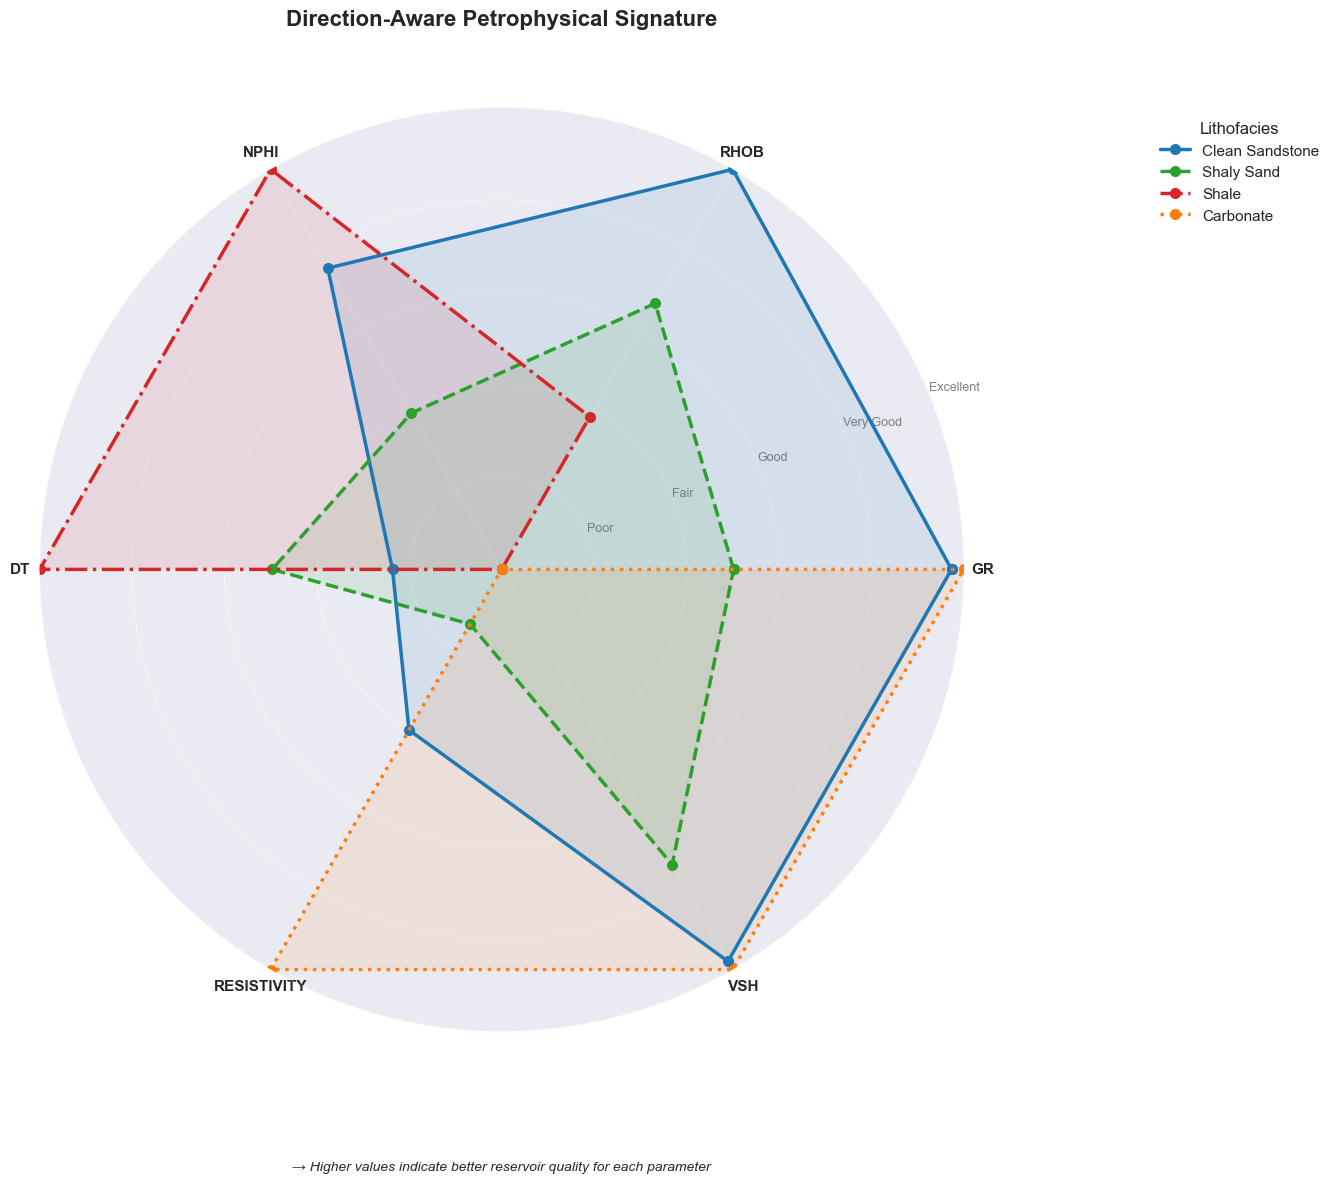

In [17]:
def create_direction_aware_radar(zone_means, title="Direction-Aware Petrophysical Signature"):
    """
    Create radar chart with petrophysics-aware normalization
    """
    # Get categories (log names) and zones (lithofacies names)
    zones = list(zone_means.keys())  # ['Clean Sandstone', 'Shaly Sand', ...]
    categories = list(zone_means[zones[0]].keys())  # ['GR', 'RHOB', 'NPHI', ...]
    N = len(categories)
    
    angles = [n / float(N) * 2 * pi for n in range(N)]
    angles += angles[:1]
    
    fig, ax = plt.subplots(figsize=(12, 12), subplot_kw=dict(projection='polar'))
    
    # Petrophysical "good" directions (1 = higher is better, -1 = lower is better)
    direction_preference = {
        'GR': -1,        # Lower GR is better (less shale)
        'RHOB': -1,      # Lower density often indicates porosity
        'NPHI': 1,       # Higher porosity is better
        'DT': 1,         # Higher DT can indicate porosity
        'RESISTIVITY': 1, # Higher resistivity is better
        'VSH': -1        # Lower shale volume is better
    }
    
    # Normalize with direction awareness
    normalized_data = {}
    for zone in zones:
        values = [zone_means[zone][cat] for cat in categories]
        
        # For each log, normalize based on preferred direction
        normalized_values = []
        for i, cat in enumerate(categories):
            direction = direction_preference[cat]
            
            # Get all values for this log across all zones
            all_values = [zone_means[z][cat] for z in zones]
            min_val = min(all_values)
            max_val = max(all_values)
            
            if direction == 1:  # Higher is better
                norm_val = (values[i] - min_val) / (max_val - min_val)
            else:  # Lower is better
                norm_val = 1 - (values[i] - min_val) / (max_val - min_val)
            
            normalized_values.append(norm_val)
        
        normalized_values += normalized_values[:1]
        normalized_data[zone] = normalized_values
    
    # Plot - Fixed: removed redundant linestyle specification
    colors = ['#1f77b4', '#2ca02c', '#d62728', '#ff7f0e']
    line_styles = ['-', '--', '-.', ':']
    
    for i, (zone, color) in enumerate(zip(zones, colors)):
        values = normalized_data[zone]
        ax.plot(angles, values, linewidth=2.5, label=zone, color=color, 
                linestyle=line_styles[i], marker='o', markersize=8)
        ax.fill(angles, values, alpha=0.1, color=color)
    
    # Enhanced formatting
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(categories, fontsize=11, fontweight='bold')
    
    # Add quality rings
    plt.yticks([0.2, 0.4, 0.6, 0.8, 1.0], 
               ["Poor", "Fair", "Good", "Very Good", "Excellent"], 
               color="grey", size=9)
    ax.set_ylim(0, 1)
    
    ax.grid(True, alpha=0.3)
    ax.legend(loc='upper right', bbox_to_anchor=(1.4, 1.0), fontsize=11,
              title="Lithofacies", title_fontsize=12)
    
    plt.title(title, size=16, y=1.08, fontweight='bold')
    
    # Add interpretation guide
    ax.text(0.5, -0.15, "→ Higher values indicate better reservoir quality for each parameter", 
            transform=ax.transAxes, ha='center', fontsize=10, style='italic')
    
    return fig, ax

print("\nCreating Direction-Aware Radar Chart...")
fig, ax = create_direction_aware_radar(zone_means)
plt.show()

#### Multi-Well Zone Comparison


Creating Multi-Well Comparison Radar Chart...


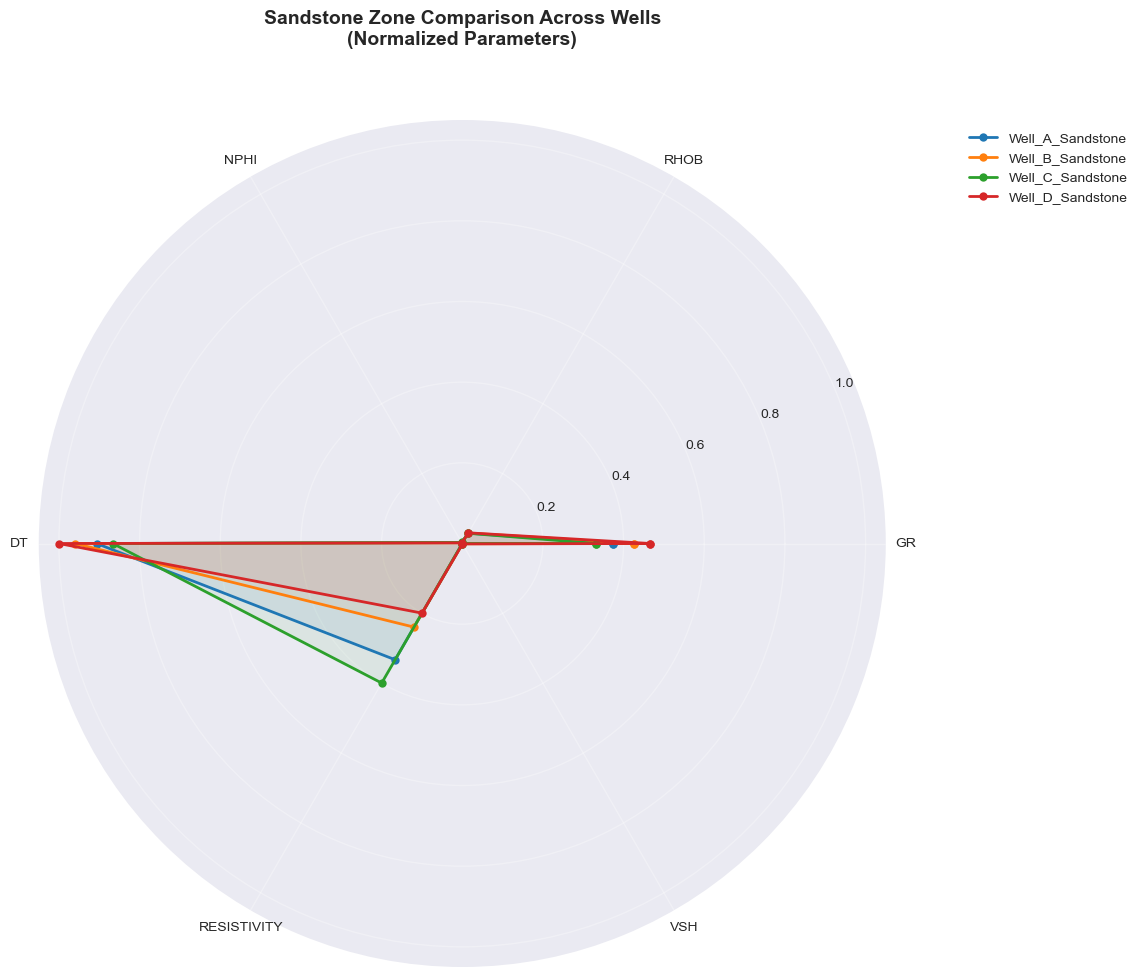

In [18]:
def create_multi_well_comparison():
    """
    Compare the same zone across different wells using radar charts
    """
    # Synthetic data for same zone across different wells
    well_data = {
        'Well_A_Sandstone': {
            'GR': 28, 'RHOB': 2.28, 'NPHI': 0.26, 'DT': 68, 'RESISTIVITY': 25, 'VSH': 0.08
        },
        'Well_B_Sandstone': {
            'GR': 32, 'RHOB': 2.32, 'NPHI': 0.22, 'DT': 72, 'RESISTIVITY': 18, 'VSH': 0.12
        },
        'Well_C_Sandstone': {
            'GR': 25, 'RHOB': 2.25, 'NPHI': 0.28, 'DT': 65, 'RESISTIVITY': 30, 'VSH': 0.06
        },
        'Well_D_Sandstone': {
            'GR': 35, 'RHOB': 2.35, 'NPHI': 0.20, 'DT': 75, 'RESISTIVITY': 15, 'VSH': 0.15
        }
    }
    
    categories = list(well_data['Well_A_Sandstone'].keys())
    wells = list(well_data.keys())
    N = len(categories)
    
    angles = [n / float(N) * 2 * pi for n in range(N)]
    angles += angles[:1]
    
    fig, ax = plt.subplots(figsize=(11, 11), subplot_kw=dict(projection='polar'))
    
    # Normalize data
    normalized_data = {}
    for well in wells:
        values = [well_data[well][cat] for cat in categories]
        
        # Min-max normalization
        min_val = min([well_data[w][cat] for cat in categories for w in wells])
        max_val = max([well_data[w][cat] for cat in categories for w in wells])
        normalized = [(x - min_val) / (max_val - min_val) for x in values]
        normalized += normalized[:1]
        normalized_data[well] = normalized
    
    # Plot each well
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
    for i, (well, color) in enumerate(zip(wells, colors)):
        values = normalized_data[well]
        ax.plot(angles, values, 'o-', linewidth=2, label=well, color=color, markersize=6)
        ax.fill(angles, values, alpha=0.08, color=color)
    
    # Formatting
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(categories, fontsize=10)
    
    ax.grid(True, alpha=0.3)
    ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.0), fontsize=10)
    plt.title("Sandstone Zone Comparison Across Wells\n(Normalized Parameters)", 
              size=14, y=1.08, fontweight='bold')
    
    return fig, ax

print("\nCreating Multi-Well Comparison Radar Chart...")
fig, ax = create_multi_well_comparison()
plt.show()

#### Statistical Radar with Confidence Intervals


Creating Statistical Radar Chart with Variability...


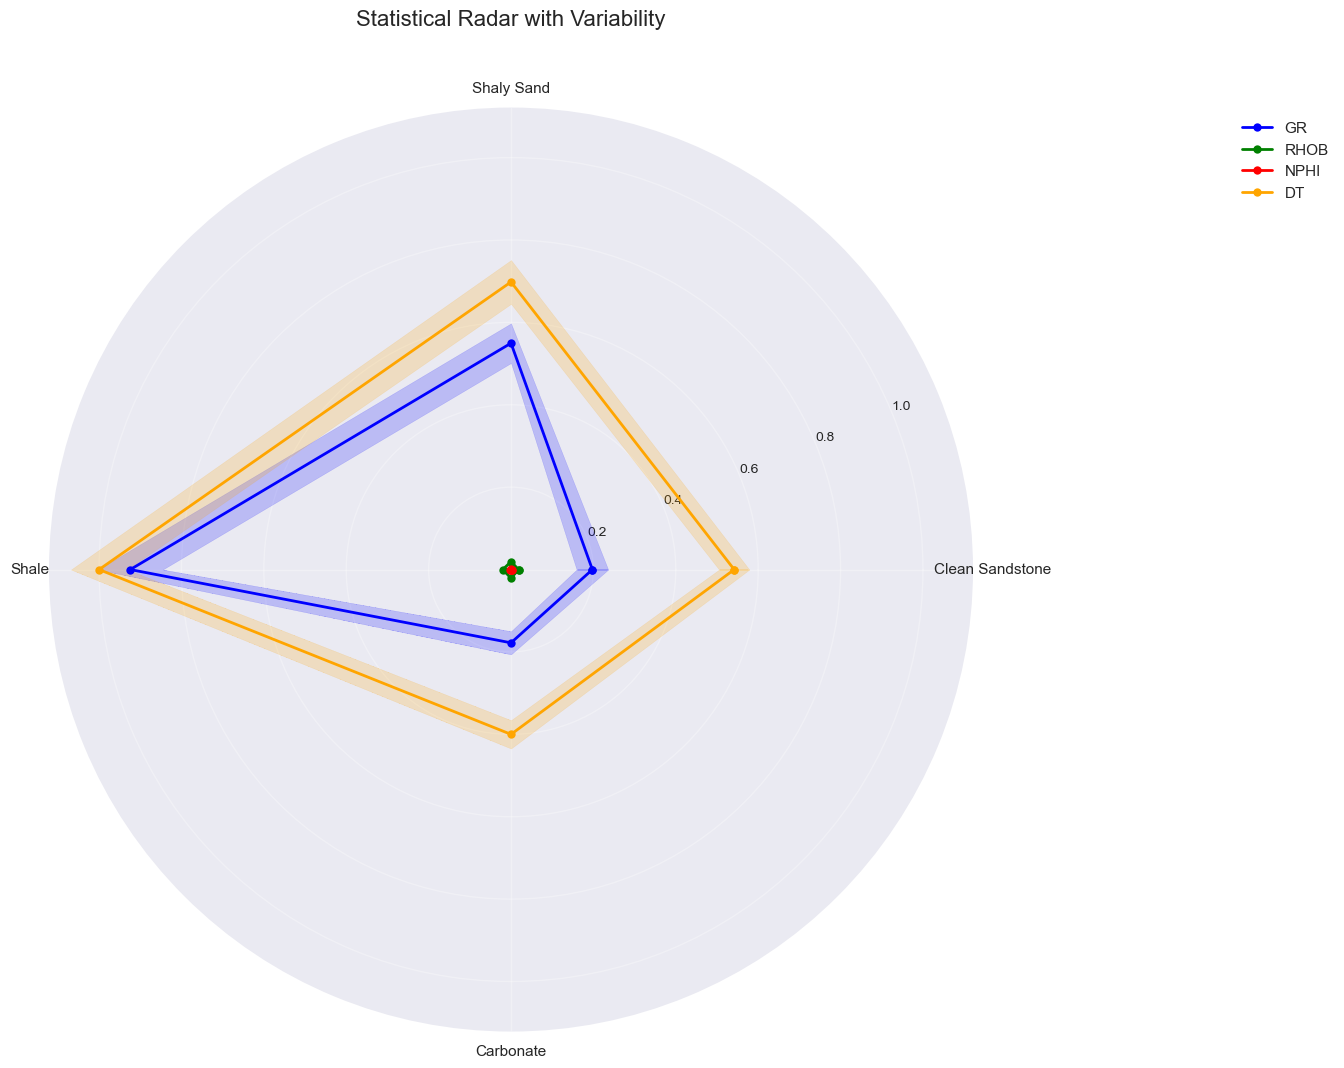

In [19]:
def create_statistical_radar(zone_data, title="Statistical Radar with Variability"):
    """
    Create radar chart showing mean ± standard deviation
    """
    categories = list(zone_data.keys())
    zones = list(zone_data[categories[0]].keys())
    N = len(categories)
    
    angles = [n / float(N) * 2 * pi for n in range(N)]
    angles += angles[:1]
    
    fig, ax = plt.subplots(figsize=(12, 12), subplot_kw=dict(projection='polar'))
    
    # Calculate means and standard deviations
    zone_stats = {}
    for zone in zones:
        means = [np.mean(zone_data[cat][zone]) for cat in categories]
        stds = [np.std(zone_data[cat][zone]) for cat in categories]
        
        # Normalize
        all_means = [np.mean(zone_data[cat][z]) for cat in categories for z in zones]
        min_val, max_val = min(all_means), max(all_means)
        
        norm_means = [(m - min_val) / (max_val - min_val) for m in means]
        norm_stds = [s / (max_val - min_val) for s in stds]
        
        norm_means += norm_means[:1]
        norm_stds += norm_stds[:1]
        
        zone_stats[zone] = {'means': norm_means, 'stds': norm_stds}
    
    # Plot with confidence intervals
    colors = ['blue', 'green', 'red', 'orange']
    for i, (zone, color) in enumerate(zip(zones, colors)):
        means = zone_stats[zone]['means']
        stds = zone_stats[zone]['stds']
        
        # Plot mean line
        ax.plot(angles, means, 'o-', linewidth=2, label=zone, color=color, markersize=6)
        
        # Plot confidence interval
        upper = [m + s for m, s in zip(means, stds)]
        lower = [m - s for m, s in zip(means, stds)]
        ax.fill_between(angles, lower, upper, alpha=0.2, color=color)
    
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(categories, fontsize=11)
    ax.grid(True, alpha=0.3)
    ax.legend(loc='upper right', bbox_to_anchor=(1.4, 1.0), fontsize=11)
    plt.title(title, size=16, y=1.08)
    
    return fig, ax

print("\nCreating Statistical Radar Chart with Variability...")
fig, ax = create_statistical_radar(zone_data)
plt.show()

#### Practical Applications in Petrophysics

In [20]:
print("\n" + "="*70)
print("PRACTICAL APPLICATIONS OF RADAR CHARTS IN PETROPHYSICS")
print("="*70)

applications = {
    "Facies Classification": [
        "• Visual fingerprint for each lithofacies",
        "• Quick identification of zone types",
        "• Training tool for junior petrophysicists"
    ],
    "Reservoir Quality Assessment": [
        "• Compare reservoir potential across zones",
        "• Identify best completion intervals", 
        "• Rank zones for production priority"
    ],
    "Multi-Well Analysis": [
        "• Correlate zones across field",
        "• Identify lateral facies changes",
        "• Understand depositional environment variations"
    ],
    "Time-Lapse Monitoring": [
        "• Track changes in reservoir properties over time",
        "• Monitor effects of production/injection",
        "• Identify bypassed pay zones"
    ],
    "Uncertainty Visualization": [
        "• Show statistical ranges of properties",
        "• Compare interpretation uncertainties",
        "• Support risk assessment in volumetrics"
    ]
}

for application, uses in applications.items():
    print(f"\n📊 {application}:")
    for use in uses:
        print(f"   {use}")

print("\n" + "="*70)
print("BEST PRACTICES FOR PETROPHYSICAL RADAR CHARTS")
print("="*70)

best_practices = [
    "1. **Always normalize data** - different units and scales make raw charts meaningless",
    "2. **Consider directionality** - know whether high or low values are 'good' for each log",
    "3. **Use consistent parameter order** - keep log types in same sequence for comparison",
    "4. **Limit to 5-8 parameters** - too many axes make charts unreadable", 
    "5. **Include reference cases** - show known end-member facies for comparison",
    "6. **Use color coding** - consistent colors help quick zone identification",
    "7. **Add statistical ranges** - show variability, not just means",
    "8. **Provide interpretation guide** - explain what the chart patterns mean geologically"
]

for practice in best_practices:
    print(f"• {practice}")


PRACTICAL APPLICATIONS OF RADAR CHARTS IN PETROPHYSICS

📊 Facies Classification:
   • Visual fingerprint for each lithofacies
   • Quick identification of zone types
   • Training tool for junior petrophysicists

📊 Reservoir Quality Assessment:
   • Compare reservoir potential across zones
   • Identify best completion intervals
   • Rank zones for production priority

📊 Multi-Well Analysis:
   • Correlate zones across field
   • Identify lateral facies changes
   • Understand depositional environment variations

📊 Time-Lapse Monitoring:
   • Track changes in reservoir properties over time
   • Monitor effects of production/injection
   • Identify bypassed pay zones

📊 Uncertainty Visualization:
   • Show statistical ranges of properties
   • Compare interpretation uncertainties
   • Support risk assessment in volumetrics

BEST PRACTICES FOR PETROPHYSICAL RADAR CHARTS
• 1. **Always normalize data** - different units and scales make raw charts meaningless
• 2. **Consider directionality

#### Interpretation Examples

In [21]:
print("\n" + "="*60)
print("INTERPRETING RADAR CHART PATTERNS")
print("="*60)

interpretation_guide = {
    "Large, symmetrical shape": "Good reservoir quality across all parameters",
    "Asymmetrical shape": "Mixed reservoir characteristics - may indicate transition zones", 
    "Small, compact shape": "Poor reservoir quality - likely non-reservoir rock",
    "Pointed spikes in specific directions": "Excellent in certain properties but poor in others",
    "Similar shapes across wells": "Consistent facies or reservoir character",
    "Different shapes across wells": "Facies changes or different depositional environments"
}

print("\nCommon Radar Chart Patterns and Their Meanings:")
for pattern, meaning in interpretation_guide.items():
    print(f"🎯 '{pattern}': {meaning}")

print(f"""
\n**Example Workflow:**
1. **Data Preparation**: Select key petrophysical parameters for comparison
2. **Normalization**: Apply min-max or z-score normalization  
3. **Chart Creation**: Plot zones with consistent color scheme
4. **Pattern Recognition**: Identify characteristic shapes and outliers
5. **Geological Interpretation**: Relate patterns to depositional environment
6. **Quality Ranking**: Use chart area and symmetry to rank reservoir quality
7. **Decision Support**: Guide completion strategies and field development
""")


INTERPRETING RADAR CHART PATTERNS

Common Radar Chart Patterns and Their Meanings:
🎯 'Large, symmetrical shape': Good reservoir quality across all parameters
🎯 'Asymmetrical shape': Mixed reservoir characteristics - may indicate transition zones
🎯 'Small, compact shape': Poor reservoir quality - likely non-reservoir rock
🎯 'Pointed spikes in specific directions': Excellent in certain properties but poor in others
🎯 'Similar shapes across wells': Consistent facies or reservoir character
🎯 'Different shapes across wells': Facies changes or different depositional environments


**Example Workflow:**
1. **Data Preparation**: Select key petrophysical parameters for comparison
2. **Normalization**: Apply min-max or z-score normalization  
3. **Chart Creation**: Plot zones with consistent color scheme
4. **Pattern Recognition**: Identify characteristic shapes and outliers
5. **Geological Interpretation**: Relate patterns to depositional environment
6. **Quality Ranking**: Use chart area and 

#### Key Advantages for Petrophysicists

In [22]:
print("\n" + "="*50)
print("WHY RADAR CHARTS WORK WELL FOR PETROPHYSICS")
print("="*50)

advantages = [
    "✅ **Multivariate Visualization**: See 6+ parameters simultaneously",
    "✅ **Pattern Recognition**: Human brain excels at recognizing shapes", 
    "✅ **Quick Comparison**: Immediately spot differences between zones",
    "✅ **Quality Assessment**: Chart area correlates with overall reservoir quality",
    "✅ **Anomaly Detection**: Irregular shapes highlight unusual zones",
    "✅ **Communication Tool**: Easy to explain to non-technical stakeholders",
    "✅ **Integration**: Combine well logs, core data, and production information"
]

for advantage in advantages:
    print(advantage)

print(f"""
\n**Final Recommendation:**
Use radar charts as a **complementary tool** alongside traditional crossplots 
and log displays. They excel at:
• Quick zone classification
• Multi-well correlation  
• Reservoir quality ranking
• Team communication and training

Combine with machine learning for automated facies classification based on
radar chart patterns!
""")


WHY RADAR CHARTS WORK WELL FOR PETROPHYSICS
✅ **Multivariate Visualization**: See 6+ parameters simultaneously
✅ **Pattern Recognition**: Human brain excels at recognizing shapes
✅ **Quick Comparison**: Immediately spot differences between zones
✅ **Quality Assessment**: Chart area correlates with overall reservoir quality
✅ **Anomaly Detection**: Irregular shapes highlight unusual zones
✅ **Communication Tool**: Easy to explain to non-technical stakeholders
✅ **Integration**: Combine well logs, core data, and production information


**Final Recommendation:**
Use radar charts as a **complementary tool** alongside traditional crossplots 
and log displays. They excel at:
• Quick zone classification
• Multi-well correlation  
• Reservoir quality ranking
• Team communication and training

Combine with machine learning for automated facies classification based on
radar chart patterns!

